# K-Nearest Neighbours

## Recap: where we left off

The Linear/Logistic Regression notebook trained models on the same two
targets we'll use again here: `log_repayment_amount` and
`repayment_probability`. Both are **parametric models**, they learn a fixed
set of coefficients, and once fit, every prediction is just a weighted sum
of the features.

## What's different in this notebook

**K-Nearest Neighbours (KNN)** is a fundamentally different kind of model:
it's **instance-based**, there are no coefficients to learn. A prediction for
a new account is made by finding the `k` most similar accounts already seen
(by distance in feature space) and averaging (regression) or voting
(classification) over their outcomes.

This difference introduces several new concepts the Linear/Logistic
Regression notebook didn't need:

- **Cross-validation**: that notebook never tuned a hyperparameter, so
  train/test was enough. KNN's `k` needs tuning, and tuning against the test
  set would leak information into a number we're supposed to report
  honestly at the end. We need a proper validation strategy
- **Time-series cross-validation**: this dataset is temporal (date-based
  split), so standard k-fold CV would let the model train on future data to
  predict the past, we need a CV scheme that respects time
- **The curse of dimensionality**: KNN relies on distance between points
  being meaningful. The Linear/Logistic Regression notebook one-hot encoded
  9 categorical columns into dozens of dummy features, a lot of dimensions
  for a distance-based model
- **Distance metrics**: unlike linear/logistic regression, which don't care
  how features relate to each other, KNN's entire behaviour depends on how
  distance is defined

## What this notebook does

- Loads `cleaned_dataset.pkl` fresh, same setup as the Linear/Logistic
  Regression notebook (encoding, feature list, missing values), standalone,
  no dependency on that notebook having been run
- Introduces k-fold and time-series cross-validation
- Demonstrates the curse of dimensionality directly on this feature matrix
- Compares distance metrics
- Tunes `k` and distance metric with `GridSearchCV`
- Trains KNN on both targets, same evaluation conventions as before
- Compares results back to the logistic/linear baselines

## 1. Setup and Data Preparation

### 1.1 Imports and loading the data

In [35]:
import pandas as pd     # DataFrame operations: loading, filtering, joining
import numpy as np      # numeric arrays and math (log/exp transforms, NaN handling)
import matplotlib.pyplot as plt  # base plotting
import seaborn as sns   # statistical plots (heatmaps, distribution plots) built on matplotlib
from scipy import stats # statistical tests (normality, group comparisons)

# Load the feature matrix produced by the EDA notebook. One row per account,
# features and all five targets already joined, split label already assigned
DATA_DIR = "data/"
master = pd.read_pickle(DATA_DIR + 'cleaned_dataset.pkl')

print(f'Loaded: {master.shape[0]:,} rows, {master.shape[1]} columns')
print()
print('Split sizes:')
print(master['split'].value_counts())

Loaded: 13,945 rows, 31 columns

Split sizes:
split
train      8968
val        3115
test       1547
unknown     315
Name: count, dtype: int64


### 1.2 Removing accounts with no split assigned

In [36]:
##########################################
## Drop accounts with no split assigned ##
##########################################
# Drop the accounts with no valid split assignment (outside the defined
# date ranges in the EDA notebook), they can't be used for train/val/test
# comparison
master = master[master['split'] != 'unknown'].copy()

print(f'Rows after dropping unknown split: {len(master):,}')

Rows after dropping unknown split: 13,630


### 1.3 Encoding remaining categorical features

The EDA notebook already ordinal-encoded `income_band` and `education_level`,
since those have a natural order. The remaining categorical columns
(`debt_type`, `status`, `city`, `gender`, `household_type`, `employment_status`,
`urban_category`, `country_of_origin`, `born_in_netherlands`) are nominal, no
inherent ordering, so they need **one-hot encoding** instead, same as the
Linear/Logistic Regression notebook. The encoder is **fit on train only**.

In [ ]:
######################################################
##    One-hot encode remaining nominal variables    ##
######################################################
from sklearn.preprocessing import OneHotEncoder  # encodes nominal variables as dummy columns, fit on train only to avoid leakage

# Categorical columns still needing one-hot encoding (income_band and
# education_level were already ordinal-encoded in the EDA notebook)
nominal_cols = ['debt_type', 'status', 'city', 'gender', 'household_type',
                'employment_status', 'urban_category', 'country_of_origin',
                'born_in_netherlands']
# Keep only the expected nominal columns that actually exist in master, so
# a missing/renamed column doesn't crash the encoder with a KeyError
nominal_cols = [c for c in nominal_cols if c in master.columns]

# Fit the encoder using only the train rows, so val/test categories can
# never influence what the encoder learns. astype(str) after fillna is
# needed because born_in_netherlands mixes Python bool (True/False) with
# the 'unknown' string, which breaks OneHotEncoder's internal sort
train_data = master[master['split'] == 'train']
enc = OneHotEncoder(sparse_output=False, handle_unknown='ignore', drop='first')
enc.fit(train_data[nominal_cols].fillna('unknown').astype(str))

# Apply the train-fitted encoder to the FULL table (train + val + test),
# filling missing categories the same way as when the encoder was fit
encoded = enc.transform(master[nominal_cols].fillna('unknown').astype(str))

# get_feature_names_out returns names like 'debt_type_Credit card', so the
# origin column and category are both visible in the resulting column names
encoded_cols = enc.get_feature_names_out(nominal_cols)

##########################################
## Attach the encoded columns to master ##
##########################################
# Wrap the encoded array back into a DataFrame, keeping master's original
# index so it lines up row-for-row for the concat below
encoded_df = pd.DataFrame(encoded, columns=list(encoded_cols), index=master.index)

# Attach the new dummy columns onto master as additional columns (axis=1),
# the original nominal_cols stay in master too, unused as model input but
# kept for reference/readability
master = pd.concat([master, encoded_df], axis=1)

print(f'One-hot encoded {len(nominal_cols)} columns into {len(encoded_cols)} dummy columns')
print(f'Master shape after encoding: {master.shape}')

One-hot encoded 9 columns into 51 dummy columns
Master shape after encoding: (13630, 82)


In [38]:
# Quick sanity check: confirm the new dummy columns were attached correctly
master.head()

,account_id,debtor_id,split,log_original_amount,log_outstanding_balance,log_days_past_due,missed_payments,interest_rate,broken_arrangements,age_at_default,...,country_of_origin_Moroccan origin,country_of_origin_Other African origin,country_of_origin_Other Asian origin,country_of_origin_Other European origin,country_of_origin_Other origin,country_of_origin_Surinamese origin,country_of_origin_Turkish origin,country_of_origin_unknown,born_in_netherlands_True,born_in_netherlands_unknown
0,9ccc6dc7-8e96-4d43-92aa-49bb044bb08a,aa7588f7-dd4a-4a7f-bff8-54da2fab20a2,val,7.022289,6.739206,5.236442,7.0,17.05,1.0,60.416153,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,39866796-bbf7-43b7-a552-a5e4c1fb4354,aa7588f7-dd4a-4a7f-bff8-54da2fab20a2,train,6.009255,6.237406,6.762730,29.0,11.59,1.0,58.568104,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,eaba36a0-8e5e-4e17-a55d-b91d60c1e06f,77a6c22c-dc7f-4a6f-ae7f-fe7a1b3305f5,val,5.573218,4.815836,5.342334,6.0,0.00,2.0,51.874059,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,eedc8d1a-6c22-441d-ab43-75c83467b96a,77a6c22c-dc7f-4a6f-ae7f-fe7a1b3305f5,train,6.945321,7.006722,5.805135,11.0,14.62,4.0,50.384668,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,38396424-7631-4b1c-92ce-af0ed2ad320e,4be5cd8c-959c-4765-92ac-e297f192aaf2,train,7.821663,7.091542,4.779123,2.0,9.34,0.0,72.914442,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


### 1.4 Defining the feature set

In [39]:
############################
## Define the feature set ##
############################
# Numeric features engineered in the EDA notebook (log-transformed amounts,
# dates, encoded ordinal categoricals, and data-quality flags)
numeric_features = ['log_original_amount', 'log_outstanding_balance', 'log_days_past_due',
                    'missed_payments', 'interest_rate', 'broken_arrangements',
                    'age_at_default', 'default_month', 'default_year',
                    'income_band_encoded', 'education_level_encoded',
                    'balance_capped', 'default_date_imputed']

# One-hot encoded dummy columns created in the previous cell
dummy_features = list(encoded_cols)

# The full feature list used to train every model in this notebook
feature_cols = numeric_features + dummy_features
print(f'Total features: {len(feature_cols)}')

Total features: 64


### 1.5 Checking for missing values

As found in the Linear/Logistic Regression notebook, `log_days_past_due` and
`broken_arrangements` still have a small number of nulls that were never
imputed in the EDA notebook. Same fix: drop them, since the affected rows
are small and spread evenly across splits.

In [40]:
##################################################
## Check for and drop rows with missing values  ##
##################################################
# StandardScaler and sklearn's models cannot handle NaN, so any missing
# values left in the feature columns need to be found and dropped now
null_counts = master[feature_cols].isna().sum()
null_counts = null_counts[null_counts > 0].sort_values(ascending=False)

if len(null_counts) > 0:
    print('Columns with remaining missing values:')
    print(null_counts)
else:
    print('No missing values found in the feature columns.')

# Drop rows with any missing feature value, same justification as the
# Linear/Logistic Regression notebook: small, evenly spread across splits
rows_before = len(master)
master = master.dropna(subset=feature_cols).copy()
rows_dropped = rows_before - len(master)

print()
print(f'Dropped {rows_dropped} rows with missing feature values ({rows_dropped/rows_before*100:.2f}% of data)')
print()
print('Split sizes after dropping:')
print(master['split'].value_counts())

Columns with remaining missing values:
log_days_past_due      68
broken_arrangements    41
dtype: int64

Dropped 109 rows with missing feature values (0.80% of data)

Split sizes after dropping:
split
train    8894
val      3090
test     1537
Name: count, dtype: int64


## 2. Hyperparameter Tuning: Train / Validation / Test

### 2.1 Why we need a validation set now

The Linear/Logistic Regression notebook only used `train` and `test`, since
nothing there was tuned. KNN has hyperparameters to choose, `k` (the number
of neighbours) and the distance metric, and choosing them by checking
performance on test would leak test information into a modelling decision.

The fix: split off a third set, **validation**, from the data we're allowed
to look at while modelling. We fit the model on `train`, compare different
hyperparameter choices by their performance on `validation`, and only once a
choice is made do we check `test`, once, to report final performance.

- **Train**: what the model learns from
- **Validation**: what we use to compare hyperparameter choices
- **Test**: touched exactly once, at the very end, to report honest performance

In [41]:
##########################################################
## Extract train, validation, and test                  ##
##########################################################
# Unlike the Linear/Logistic Regression notebook, we need all three splits
# here, since we're tuning a hyperparameter
df_train = master[master['split'] == 'train']
df_val   = master[master['split'] == 'val']
df_test  = master[master['split'] == 'test']

X_train = df_train[feature_cols]
X_val   = df_val[feature_cols]
X_test  = df_test[feature_cols]

print(f'X_train: {X_train.shape}, X_val: {X_val.shape}, X_test: {X_test.shape}')

##########################################################
## Scale: fit on train only, apply to all three          ##
##########################################################
from sklearn.preprocessing import StandardScaler  # standardises features to mean 0, std 1; essential for KNN since it's distance-based

scaler = StandardScaler()
scaler.fit(X_train)  # fit on train only, same rule as every other transform in this project

X_train_scaled = pd.DataFrame(scaler.transform(X_train), columns=feature_cols, index=X_train.index)
X_val_scaled   = pd.DataFrame(scaler.transform(X_val),   columns=feature_cols, index=X_val.index)
X_test_scaled  = pd.DataFrame(scaler.transform(X_test),  columns=feature_cols, index=X_test.index)

X_train: (8894, 64), X_val: (3090, 64), X_test: (1537, 64)


### 2.2 KNN's hyperparameters: k and distance metric

KNN has two choices to make before it can predict anything, both are
hyperparameters, values we choose, not values the model learns from data:

**1. k, the number of neighbours**

How many of the closest training points to look at when making a prediction.
For classification, the predicted class is a (majority or weighted) vote
among the `k` neighbours' labels. For regression, it's their average.

- Small `k` → prediction depends on very few points → sensitive to noise in
  those specific points
- Large `k` → prediction averages over many points → smoother, but can blur
  over real local patterns

**2. The distance metric**

"Nearest" neighbours requires a definition of distance between two rows in
feature space. Different metrics define it differently, and which neighbours
count as "closest" can change depending on which one you pick:

- **Euclidean distance**: straight-line distance, the familiar one
$$d(x, y) = \sqrt{\sum_i (x_i - y_i)^2}$$
- **Manhattan distance**: sum of absolute differences along each feature,
  like navigating a city grid rather than cutting across diagonally
$$d(x, y) = \sum_i |x_i - y_i|$$
- **Minkowski distance**: a generalisation of both, Euclidean and Manhattan
  are special cases of it
$$d(x, y) = \left(\sum_i |x_i - y_i|^p\right)^{1/p}$$
  `p=2` gives Euclidean, `p=1` gives Manhattan. `p` itself becomes a tunable
  value, not just a choice between two fixed options.

Neither hyperparameter has one objectively correct value, both depend on the
data, which is exactly why we tune them against validation rather than
picking one on theory alone.

### 2.3 Trying combinations of k and distance metric for predicting 'repayment_probability'

Rather than nested loops, we write a small function that evaluates one
`(k, metric)` combination, then apply it across every combination using
`itertools.product` and `map`. This is a more functional style: a pure
function with no side effects, combined with built-in tools for generating
and applying combinations, rather than manually writing nested `for` loops.


We first tune `k` and the distance metric for the **classification** problem
(`repayment_probability`). The same approach will be repeated for the
**regression** target (`log_repayment_amount`) later in this notebook.

First, we define what we want to predict: the labels for each split.

In [43]:
##########################################################
## Extract the classification labels for every split     ##
##########################################################
# Labels for the classification target, taken from the same original splits
y_train_clf = df_train['repayment_probability']  # train labels
y_val_clf   = df_val['repayment_probability']    # validation labels
y_test_clf  = df_test['repayment_probability']   # test labels (not used until the final evaluation)

print(f'y_train_clf: {y_train_clf.shape}, y_val_clf: {y_val_clf.shape}, y_test_clf: {y_test_clf.shape}')

y_train_clf: (8894,), y_val_clf: (3090,), y_test_clf: (1537,)


In [42]:
##########################################################
## A reusable, pure function: evaluate one (k, metric)  ##
## combination, with all data passed in explicitly      ##
##########################################################
from itertools import product  # generates every combination of two (or more) iterables
from sklearn.neighbors import KNeighborsClassifier  # instance-based classifier
from sklearn.metrics import f1_score  # F1, not accuracy, per the class-imbalance lesson from the Linear/Logistic Regression notebook

def evaluate_knn(k, metric, X_tr, y_tr, X_va, y_va):
    """Fits a KNeighborsClassifier for one (k, metric) combination and scores it.

    A pure function: given the same inputs, it always returns the same
    result, and it never reads or modifies anything outside its own
    arguments. This makes it safe to call repeatedly via map(), and easy to
    test or reuse on different data without hidden dependencies.

    Args:
        k (int): Number of neighbours.
        metric (str): Distance metric, e.g. 'euclidean' or 'manhattan'.
        X_tr (pd.DataFrame): Scaled training features.
        y_tr (pd.Series): Training labels.
        X_va (pd.DataFrame): Scaled validation features.
        y_va (pd.Series): Validation labels.

    Returns:
        dict: {'k', 'metric', 'train_f1', 'val_f1'}, the hyperparameters
            tried and the resulting F1 scores on train and validation.
    """
    # KNN has no class_weight parameter, unlike logistic regression, so
    # class imbalance isn't corrected here
    knn = KNeighborsClassifier(n_neighbors=k, metric=metric)
    knn.fit(X_tr, y_tr)

    train_f1 = f1_score(y_tr, knn.predict(X_tr))
    val_f1   = f1_score(y_va, knn.predict(X_va))

    return {'k': k, 'metric': metric, 'train_f1': train_f1, 'val_f1': val_f1}

In [32]:
##########################################################
## Apply the function to every (k, metric) combination   ##
##########################################################

k_values = [1, 5, 15, 50]
metrics_to_try = ['euclidean', 'manhattan']

# product() generates every pairing of the two lists, e.g. (1, 'euclidean'),
# (1, 'manhattan'), (5, 'euclidean'), ... so there's no manual nested loop
combinations = product(k_values, metrics_to_try)

# A plain list comprehension, calling evaluate_knn directly for each
# (k, metric) pair, no lambda needed
results = [evaluate_knn(k, metric, X_train_scaled, y_train_clf, X_val_scaled, y_val_clf)
          for k, metric in combinations]

results_df = pd.DataFrame(results).sort_values('val_f1', ascending=False)
results_df

,k,metric,train_f1,val_f1
1,1,manhattan,1.000000,0.417605
0,1,euclidean,1.000000,0.391710
3,5,manhattan,0.598632,0.384807
5,15,manhattan,0.475560,0.340000
2,5,euclidean,0.558467,0.333119
4,15,euclidean,0.369505,0.236378
7,50,manhattan,0.272830,0.199021
6,50,euclidean,0.135357,0.080560


### What we observe

- **k=1 shows perfect train F1 (1.000) for both metrics**, exactly what the
  theory predicts: with one neighbour, every training point is trivially its
  own nearest neighbour, the model "memorises" the training data completely
- **But k=1's validation F1 (0.42, 0.39) is also the highest of all
  combinations**, not what the pure overfitting story would suggest. The gap
  between train and validation F1 is enormous (1.000 → ~0.40), confirming
  real overfitting, but k=1 still wins on validation here
- **Validation F1 falls steadily as k increases**: 0.42 → 0.38 → 0.34 → 0.24 → 0.08,
  monotonically, no sweet spot in the middle of this particular range. Larger
  k keeps hurting, never helping
- **Manhattan distance beats Euclidean at every k tested**, worth sitting
  with given this feature matrix is dominated by one-hot encoded dummy
  columns, a question for the dimensionality section coming up


  **QUESTION**: The validation F1 trend is monotonically decreasing across every k tested, no interior minimum. What does that suggest about whether k=1 is truly optimal, or whether the search range was too coarse? What would you try next to find out?

In [ ]:
##########################################################
##          Finer k sweep near the small-k region       ##
##########################################################
k_values_fine = [1, 2, 3, 4, 5, 7, 10]
metrics_to_try = ['euclidean', 'manhattan']

combinations = product(k_values_fine, metrics_to_try)
results_fine = [evaluate_knn(k, metric, X_train_scaled, y_train_clf, X_val_scaled, y_val_clf)
                for k, metric in combinations]

results_fine_df = pd.DataFrame(results_fine).sort_values('val_f1', ascending=False)
results_fine_df

,k,metric,train_f1,val_f1
1,1,manhattan,1.000000,0.417605
5,3,manhattan,0.696133,0.407429
0,1,euclidean,1.000000,0.391710
9,5,manhattan,0.598632,0.384807
11,7,manhattan,0.567789,0.362080
4,3,euclidean,0.665468,0.359420
8,5,euclidean,0.558467,0.333119
10,7,euclidean,0.499702,0.298103
7,4,manhattan,0.504596,0.276306
13,10,manhattan,0.446691,0.276219


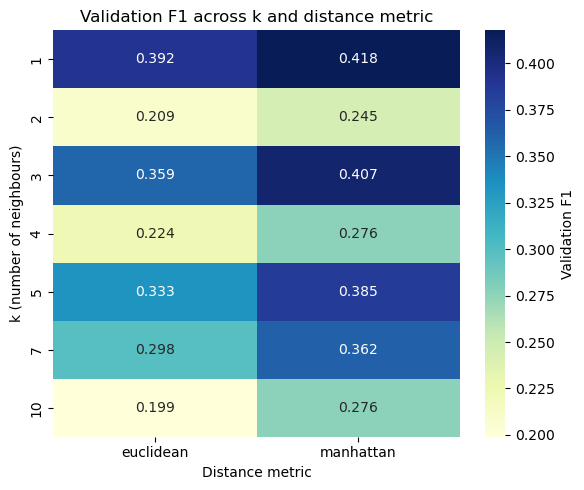

In [11]:
##########################################################
## Heatmap: validation F1 across k and distance metric  ##
##########################################################
# Pivot into a k x metric matrix of val_f1 values
heatmap_data = results_fine_df.pivot(index='k', columns='metric', values='val_f1')

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(heatmap_data, annot=True, fmt='.3f', cmap='YlGnBu', ax=ax,
           cbar_kws={'label': 'Validation F1'})
ax.set_title('Validation F1 across k and distance metric')
ax.set_xlabel('Distance metric')
ax.set_ylabel('k (number of neighbours)')
plt.tight_layout()
plt.show()

### What the finer sweep shows

- **k=1 is still the best**, even at finer granularity (val F1 = 0.418, manhattan), confirming this isn't an artifact of a too-coarse search, k=1 genuinely outperforms every nearby alternative
- **The decline is still mostly monotonic**, with one exception: **k=2 dips unusually low** (0.245 manhattan, 0.209 euclidean) before **k=3 partially recovers** (0.407, 0.359). A single non-monotonic point like this is often noise rather than a real pattern, worth being cautious about over-interpreting one dip
- **Manhattan distance beats Euclidean at every k tested**, now even more consistent across the finer range than before

**QUESTION:** k=1 means every prediction depends on a single nearest
neighbour, the model with the least smoothing possible. Despite showing the
clearest sign of overfitting (train F1 = 1.000), it still wins on
validation. What does that suggest about the structure of this dataset,
specifically, about how much useful signal versus noise exists in the local
neighbourhood around each point?

### 2.4 Conclusion: best hyperparameters

The finer sweep confirms **k=1, Manhattan distance** as the best combination
(validation F1 = 0.418), consistently outperforming every other combination
tested, including at finer granularity.

Now that a choice is made, validation has served its purpose. The standard
next step: **combine train and validation into one larger "fitting" set**,
refit the final model on all of it (more data should mean a better fit), and
only then evaluate on test, the one check we haven't touched until now.

In [44]:
##########################################################
## Refit on train+val with the validation-selected       ##
## hyperparameters, then evaluate on test                ##
##########################################################
# Best hyperparameters from the validation sweep
best_k_val      = 1
best_metric_val = 'manhattan'

# Fitting data = the original train and val rows combined
df_fit    = pd.concat([df_train, df_val])
X_fit     = df_fit[feature_cols]                 # unscaled fitting features
y_fit_clf = df_fit['repayment_probability']      # fitting labels

# Refit the scaler on the fitting data, then apply it to fit and test.
# New names are used so the 2.1 versions (scaled with the train-only scaler) stay untouched
scaler_fit = StandardScaler().fit(X_fit)
X_fit_scaled      = pd.DataFrame(scaler_fit.transform(X_fit),  columns=feature_cols, index=X_fit.index)   # scaled fitting features
X_test_fit_scaled = pd.DataFrame(scaler_fit.transform(X_test), columns=feature_cols, index=X_test.index)  # test scaled with the fit-data scaler

# Train the final model on the fitting data with the validation-selected hyperparameters
knn_best_val = KNeighborsClassifier(n_neighbors=best_k_val, metric=best_metric_val)
knn_best_val.fit(X_fit_scaled, y_fit_clf)

# Score on the fitting data and on test
fit_f1  = f1_score(y_fit_clf, knn_best_val.predict(X_fit_scaled))
test_f1 = f1_score(y_test_clf, knn_best_val.predict(X_test_fit_scaled))

print(f'Final model (k={best_k_val}, metric={best_metric_val})')
print(f'F1 on fitting data (train+val): {fit_f1:.3f}')
print(f'F1 on test:                     {test_f1:.3f}')

Final model (k=1, metric=manhattan)
F1 on fitting data (train+val): 1.000
F1 on test:                     0.446


### What we observe

- **F1 on the fitting data is a perfect 1.000**, expected for k=1, every
  point in the fitting set is trivially its own nearest neighbour once it's
  part of the data the model was fit on
- **F1 on test (0.446) is actually higher than the validation F1 we saw
  during tuning (0.418)**, a reasonable outcome: the final model was fit on
  more data (train+val combined) than any model during the tuning sweep,
  which only ever saw train alone
- **The gap between fitting F1 (1.000) and test F1 (0.446) looks like severe
  overfitting**, but this is the expected, structural signature of k=1, not
  a sign something went wrong. Train performance is not a meaningful
  reference point for k=1 specifically, it's mechanically guaranteed to be
  perfect regardless of how good the model actually is


**QUESTION:** Compare this test F1 (0.446) to the Linear/Logistic Regression
notebook's logistic regression F1 (0.679 on test). Which model actually
performs better on data it's never seen? Given k=1's training F1 is
meaningless by construction, what does this comparison suggest about relying
on "the model that fits training data best" versus "the model that
generalises best"?

## 3. K-Fold Cross-Validation

### 3.1 Why a single validation split isn't enough

The manual sweep in Section 2 used one fixed validation split, so each
k/metric score depends on which specific accounts happened to land in
`val`. A different split could rank the combinations differently, and
there's no way to tell, from a single split alone, whether a result is
reliable or just got lucky.

**K-fold CV** addresses this by averaging performance over several different
train/validation divisions, rather than trusting just one.

- Take the **fitting data** (`train` + `val` combined, `df_fit` from
  Section 2), now that we no longer need a single fixed validation split set
  aside, k-fold creates its own validation folds internally
- Split it into `k` equal-sized chunks ("folds")
- For each of `k` iterations: fit on `k-1` folds, evaluate on the remaining
  1 fold
- Every row gets used for validation exactly once
- Average the validation scores across all `k` iterations, this gives a
  more reliable estimate than any single split

**Test stays untouched**, same rule as before, only checked once, at the
very end, after k-fold has selected the best hyperparameters.

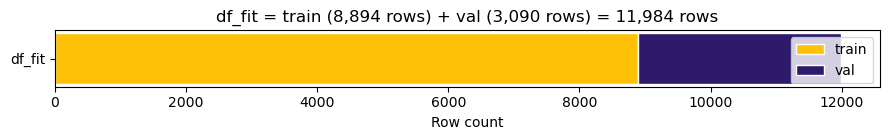

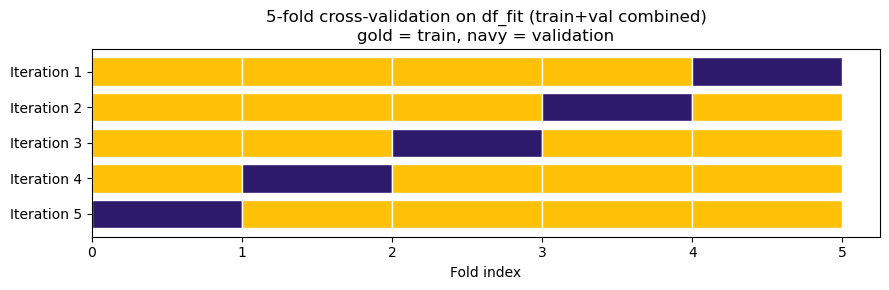

In [ ]:
##########################################################
## Diagram: df_fit = train + val combined               ##
##########################################################
navy = '#2E1A6B'
gold = '#FFC107'

n_train = len(df_train)
n_val   = len(df_val)

fig, ax = plt.subplots(figsize=(9, 1.5))

# Show train and val as two distinct segments making up df_fit, matching
# the colours used in the theory lesson: train = gold, val = navy
ax.barh(y=1, width=n_train, left=0, height=0.8, color=gold, edgecolor='white', label='train')
ax.barh(y=1, width=n_val, left=n_train, height=0.8, color=navy, edgecolor='white', label='val')

ax.set_yticks([1])
ax.set_yticklabels(['df_fit'])
ax.set_xlabel('Row count')
ax.set_title(f'df_fit = train ({n_train:,} rows) + val ({n_val:,} rows) = {n_train + n_val:,} rows')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()


##########################################################
## Diagram: how k-fold CV splits df_fit                 ##
##########################################################
n_folds = 5

fig, ax = plt.subplots(figsize=(9, 3))

for i in range(n_folds):
    # i=0 is Iteration 1, drawn at the top (y=n_folds), with the held-out
    # (gold/validation) chunk starting at the rightmost fold; it moves one
    # step to the left each subsequent iteration
    y = n_folds - i
    val_chunk = n_folds - 1 - i
    for chunk in range(n_folds):
        colour = navy if chunk == val_chunk else gold
        ax.barh(y=y, width=1, left=chunk, height=0.8, color=colour, edgecolor='white')

ax.set_yticks(range(1, n_folds + 1))
ax.set_yticklabels([f'Iteration {n_folds - y + 1}' for y in range(1, n_folds + 1)])
ax.set_xticks(range(n_folds + 1))
ax.set_xlabel('Fold index')
ax.set_title(f'{n_folds}-fold cross-validation on df_fit (train+val combined)\ngold = train, navy = validation')
plt.tight_layout()
plt.show()

### 3.2 Running k-fold CV

For each `(k, metric)` combination, we loop over the 5 folds:

- Fit the scaler on the train folds only
- Fit KNN on the scaled train folds
- Predict on the held-out val fold and record the F1 score

The **mean F1** across folds is our estimate of performance. The **standard deviation** tells us how stable that estimate is.

In [45]:
##########################################################
## A reusable function: k-fold CV for one (k, metric)    ##
##########################################################
from sklearn.model_selection import KFold  # defines how rows are divided into folds

def cv_knn(k, metric, X, y, cv):
    """Runs k-fold CV for one (k, metric) combination of a KNN classifier.

    Args:
        k (int): Number of neighbours.
        metric (str): Distance metric, e.g. 'euclidean' or 'manhattan'.
        X (pd.DataFrame): Unscaled features of the fitting data.
        y (pd.Series): Labels of the fitting data.
        cv (KFold): Fold splitter that defines the train/validation folds.

    Returns:
        dict: {'k', 'metric', 'mean_f1', 'std_f1'}, the hyperparameters tried
            and the mean and spread of F1 across folds.
    """
    fold_scores = []

    # cv.split gives the row positions of the train and val parts of each fold
    for train_idx, val_idx in cv.split(X):
        X_tr, X_va = X.iloc[train_idx], X.iloc[val_idx]  # features of this fold's train and val parts
        y_tr, y_va = y.iloc[train_idx], y.iloc[val_idx]  # labels of this fold's train and val parts

        scaler_fold = StandardScaler().fit(X_tr)   # fit the scaler on this fold's train part only
        X_tr_scaled = scaler_fold.transform(X_tr)  # scale the train part
        X_va_scaled = scaler_fold.transform(X_va)  # scale the val part with the train part's mean and std

        knn = KNeighborsClassifier(n_neighbors=k, metric=metric)
        knn.fit(X_tr_scaled, y_tr)  # fit on the train part

        fold_scores.append(f1_score(y_va, knn.predict(X_va_scaled)))  # predict on the val part, record F1

    return {'k': k, 'metric': metric,
            'mean_f1': np.mean(fold_scores),  # average performance across folds
            'std_f1': np.std(fold_scores)}    # spread across folds, high = unstable estimate

We now apply `cv_knn` to every `(k, metric)` combination, using the fitting data (`X_fit`, `y_fit_clf`) defined in 2.4.

In [46]:
##########################################################
## Apply the function to every (k, metric) combination   ##
##########################################################
kf = KFold(n_splits=5, shuffle=True, random_state=42)  # 5 folds, shuffled, reproducible

k_values_cv = [1, 3, 5, 7, 10, 15]  # grid of neighbour counts for CV

# metrics_to_try comes from 2.3 and X_fit, y_fit_clf come from 2.4, so none are redefined here
cv_results = [cv_knn(k, metric, X_fit, y_fit_clf, kf)
              for k, metric in product(k_values_cv, metrics_to_try)]

cv_results_df = pd.DataFrame(cv_results).sort_values('mean_f1', ascending=False)
cv_results_df

,k,metric,mean_f1,std_f1
3,3,manhattan,0.413673,0.009709
7,7,manhattan,0.410419,0.016891
1,1,manhattan,0.409989,0.016487
5,5,manhattan,0.406706,0.012874
11,15,manhattan,0.394907,0.014723
0,1,euclidean,0.378563,0.016921
2,3,euclidean,0.367882,0.009773
4,5,euclidean,0.350345,0.016584
9,10,manhattan,0.349115,0.016183
6,7,euclidean,0.335700,0.015067


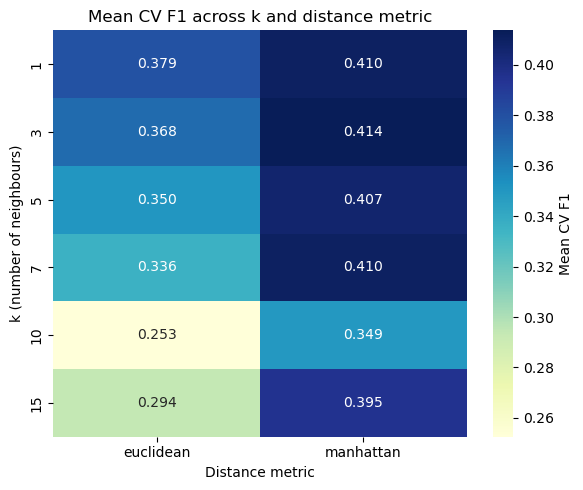

In [47]:
##########################################################
## Heatmap: mean CV F1 across k and distance metric      ##
##########################################################
# Pivot into a k x metric matrix, rows ordered by k
heatmap_data_cv = cv_results_df.pivot(index='k', columns='metric', values='mean_f1')

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(heatmap_data_cv, annot=True, fmt='.3f', cmap='YlGnBu', ax=ax,
           cbar_kws={'label': 'Mean CV F1'})  # annotate each cell with its mean F1
ax.set_title('Mean CV F1 across k and distance metric')
ax.set_xlabel('Distance metric')
ax.set_ylabel('k (number of neighbours)')
plt.tight_layout()
plt.show()

### What we observe

- The best combination by mean F1 is **k=3, Manhattan** (0.414), but k=1, 5 and 7 with Manhattan are within 0.007 of it
- Those gaps are smaller than the fold-to-fold standard deviation (0.010 to 0.017), so CV cannot separate these four settings with confidence
- In Section 2, the single validation split named k=1 as the clear winner. CV shows that ranking was partly down to which accounts landed in `val`
- Manhattan beats Euclidean at every k, consistent with Section 2
- Mean CV F1 (about 0.41) is close to the Section 2 validation F1 (0.418), so the single split was close in level, only different in ranking
- k=10 scores below both k=7 and k=15, for both metrics. With an even k, votes can tie, and ties are likely resolved in favour of class 0 (no repayment), which lowers F1 on the repayment class


**QUESTION:** Several settings (k=1, 3, 5, 7 with Manhattan) have mean F1 within one standard deviation of each other. How would you choose between them? Consider model smoothness, the spread across folds, and computation cost. Why might odd values of k be preferable for a binary classification problem?

### 3.3 Final model with the CV-selected hyperparameters

k-fold CV picked **k=3, Manhattan**. As in 2.4, we refit on the full fitting data (`df_fit`) with these hyperparameters and evaluate on test.

- `X_fit_scaled` and `X_test_fit_scaled` are reused from 2.4, since the scaler was already fit on the fitting data
- Test is checked once for this procedure, and we do not use the two test scores to choose between the two procedures

In [48]:
##########################################################
##        Refit on train+val with the CV-selected       ##
##        hyperparameters, then evaluate on test        ##
##########################################################
# Best hyperparameters from k-fold CV (top row of cv_results_df)
best_k_cv      = 3
best_metric_cv = 'manhattan'

# Train the final model on the fitting data with the CV-selected hyperparameters
knn_best_cv = KNeighborsClassifier(n_neighbors=best_k_cv, metric=best_metric_cv)
knn_best_cv.fit(X_fit_scaled, y_fit_clf)  # X_fit_scaled and y_fit_clf come from 2.4

# Score on the fitting data and on test
fit_f1_cv  = f1_score(y_fit_clf, knn_best_cv.predict(X_fit_scaled))
test_f1_cv = f1_score(y_test_clf, knn_best_cv.predict(X_test_fit_scaled))

print(f'Final model (k={best_k_cv}, metric={best_metric_cv})')
print(f'F1 on fitting data (train+val): {fit_f1_cv:.3f}')
print(f'F1 on test:                     {test_f1_cv:.3f}')

Final model (k=3, metric=manhattan)
F1 on fitting data (train+val): 0.700
F1 on test:                     0.408


### What we observe

- **F1 on the fitting data is 0.700**, no longer a perfect 1.000 as with k=1, because each prediction now averages three neighbours instead of copying one
- **F1 on test is 0.408**, very close to the CV estimate for this setting (0.414), so CV gave a reliable preview of test performance
- In 2.4, the validation-selected k=1 scored 0.446 on test, higher than the CV-selected k=3 here. We do not switch to k=1 because of this, since that would use test to make a tuning decision. A gap of this size on one test set of about 1,500 accounts may also be noise
- Both KNN models score far below the logistic regression from the Linear/Logistic Regression notebook (test F1 of about 0.68)
- KNN has no `class_weight` option, so nothing here corrects the 75/25 class imbalance, which likely hurts recall on the repayment class



**QUESTION:** The CV-selected model (k=3) scored lower on test than the validation-selected model (k=1). Does this mean CV is a worse tuning method? Consider the size of the test set, the temporal drift found in the EDA notebook (CV shuffles rows across time, while test is later in time), and why we must not use test scores to choose between the two methods.

## 4. KNN for Regression

### 4.1 Defining the regression target

We now repeat the same workflow for the **regression** target, `log_repayment_amount`.

- `KNeighborsRegressor` predicts the **average** target value of the `k` nearest neighbours, where the classifier took a majority vote
- The splits, features and scalers are the same ones we already defined, so only the labels change
- As in the Linear/Logistic Regression notebook, the model is trained on the **log scale**. To tune `k` and the metric we compare **RMSE on the log scale** (lower is better), and the final test metrics are reported in **EUR** after `np.expm1()`
- The target includes accounts that repaid nothing (a log value of 0), exactly as in the linear regression, so the two results are comparable

In [49]:
##########################################################
## Define the target: regression labels per split        ##
##########################################################
# Labels for the regression target, taken from the same original splits
y_train_reg = df_train['log_repayment_amount']  # train labels
y_val_reg   = df_val['log_repayment_amount']    # validation labels
y_test_reg  = df_test['log_repayment_amount']   # test labels (not used until the final evaluation)
y_fit_reg   = df_fit['log_repayment_amount']    # fitting labels (train + val), used for the final refit

print(f'y_train_reg: {y_train_reg.shape}, y_val_reg: {y_val_reg.shape}, '
      f'y_test_reg: {y_test_reg.shape}, y_fit_reg: {y_fit_reg.shape}')

y_train_reg: (8894,), y_val_reg: (3090,), y_test_reg: (1537,), y_fit_reg: (11984,)


### 4.2 Tuning k and the distance metric

We repeat both tuning procedures for the regression target:

- **Single validation split:** fit on train, score on val
- **K-fold CV:** 5 folds on the fitting data, with the scaler re-fit on each fold's train part

We compare **RMSE on the log scale**. The same grid of `k` values is used for both, and the hyperparameters with the lowest RMSE are selected.

In [51]:
##########################################################
## Regression tuning: validation split and k-fold CV     ##
##########################################################
from sklearn.neighbors import KNeighborsRegressor  # KNN for a continuous target: averages the neighbours' values
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score  # regression metrics

def evaluate_knn_reg(k, metric, X_tr, y_tr, X_va, y_va):
    """Fits a KNeighborsRegressor for one (k, metric) combination and scores it.

    Args:
        k (int): Number of neighbours.
        metric (str): Distance metric, e.g. 'euclidean' or 'manhattan'.
        X_tr (pd.DataFrame): Scaled training features.
        y_tr (pd.Series): Training labels (log scale).
        X_va (pd.DataFrame): Scaled validation features.
        y_va (pd.Series): Validation labels (log scale).

    Returns:
        dict: {'k', 'metric', 'train_rmse', 'val_rmse'}, the hyperparameters
            tried and the RMSE on train and validation (log scale).
    """
    knn = KNeighborsRegressor(n_neighbors=k, metric=metric)
    knn.fit(X_tr, y_tr)  # fit on the train part

    train_rmse = np.sqrt(mean_squared_error(y_tr, knn.predict(X_tr)))  # RMSE on train
    val_rmse   = np.sqrt(mean_squared_error(y_va, knn.predict(X_va)))  # RMSE on validation

    return {'k': k, 'metric': metric, 'train_rmse': train_rmse, 'val_rmse': val_rmse}


def cv_knn_reg(k, metric, X, y, cv):
    """Runs k-fold CV for one (k, metric) combination of a KNN regressor.

    Args:
        k (int): Number of neighbours.
        metric (str): Distance metric, e.g. 'euclidean' or 'manhattan'.
        X (pd.DataFrame): Unscaled features of the fitting data.
        y (pd.Series): Labels of the fitting data (log scale).
        cv (KFold): Fold splitter that defines the train/validation folds.

    Returns:
        dict: {'k', 'metric', 'mean_rmse', 'std_rmse'}, the hyperparameters
            tried and the mean and spread of RMSE across folds (log scale).
    """
    fold_scores = []

    # cv.split gives the row positions of the train and val parts of each fold
    for train_idx, val_idx in cv.split(X):
        X_tr, X_va = X.iloc[train_idx], X.iloc[val_idx]  # features of this fold's train and val parts
        y_tr, y_va = y.iloc[train_idx], y.iloc[val_idx]  # labels of this fold's train and val parts

        scaler_fold = StandardScaler().fit(X_tr)   # fit the scaler on this fold's train part only
        X_tr_scaled = scaler_fold.transform(X_tr)  # scale the train part
        X_va_scaled = scaler_fold.transform(X_va)  # scale the val part with the train part's mean and std

        knn = KNeighborsRegressor(n_neighbors=k, metric=metric)
        knn.fit(X_tr_scaled, y_tr)  # fit on the train part

        fold_scores.append(np.sqrt(mean_squared_error(y_va, knn.predict(X_va_scaled))))  # RMSE on the val part

    return {'k': k, 'metric': metric,
            'mean_rmse': np.mean(fold_scores),  # average error across folds
            'std_rmse': np.std(fold_scores)}    # spread across folds


k_values_reg = [1, 3, 5, 7, 10, 15, 25, 50]  # grid of neighbour counts, used for both procedures

# Procedure 1: single validation split (lowest val_rmse first)
results_reg = [evaluate_knn_reg(k, metric, X_train_scaled, y_train_reg, X_val_scaled, y_val_reg)
               for k, metric in product(k_values_reg, metrics_to_try)]
results_reg_df = pd.DataFrame(results_reg).sort_values('val_rmse', ascending=True)

# Procedure 2: k-fold CV on the fitting data (kf comes from 3.2; lowest mean_rmse first)
cv_results_reg = [cv_knn_reg(k, metric, X_fit, y_fit_reg, kf)
                  for k, metric in product(k_values_reg, metrics_to_try)]
cv_results_reg_df = pd.DataFrame(cv_results_reg).sort_values('mean_rmse', ascending=True)

results_reg_df  # run the next line in its own cell to see the CV table too: cv_results_reg_df

,k,metric,train_rmse,val_rmse
15,50,manhattan,1.581219,1.997813
13,25,manhattan,1.556143,2.000916
11,15,manhattan,1.529030,2.015523
14,50,euclidean,1.615721,2.025511
12,25,euclidean,1.595953,2.031494
9,10,manhattan,1.503063,2.043637
10,15,euclidean,1.562121,2.045310
8,10,euclidean,1.535730,2.067034
7,7,manhattan,1.465612,2.073357
6,7,euclidean,1.493279,2.101060


### What we observe

- Validation RMSE falls steadily as `k` grows, from 2.65 at k=1 to 2.00 at k=50, so the best setting so far is **k=50, Manhattan**
- k=1 has a train RMSE of exactly 0 and the worst validation RMSE, the same memorisation pattern as in the classification case
- Manhattan beats Euclidean at every k, as it did for classification
- **The best value sits at the edge of the grid** (k=50 is the largest value we tried), so the true optimum may be higher. This is the mirror image of the classification case, where the best value sat at the small end
- Regression prefers much larger `k` than classification did. The target mixes many zeros (non-payers) with right-skewed amounts, so averaging over many neighbours smooths out a lot of noise
- A gap between train and validation RMSE remains even at k=50 (1.58 vs 2.00)


**QUESTION:** The lowest validation RMSE is at the largest `k` we tried. What does that suggest about the search range, and what would you try next? An RMSE of 2.0 on the log scale means little on its own. What simple baseline would you compare it to?

### 4.3 Final models and test performance

As in 2.4 and 3.3, we refit each selected model on the fitting data and evaluate on test, once per procedure. Test is not used to choose between the two procedures. Metrics are reported in **EUR**, after `np.expm1()`, as `fit: %.2f, test: %.2f` pairs.

In [52]:
##########################################################
## Refit with the selected hyperparameters, test in EUR  ##
##########################################################
# Best hyperparameters = top row of each sorted results table
best_k_reg_val      = int(results_reg_df.iloc[0]['k'])
best_metric_reg_val = results_reg_df.iloc[0]['metric']
best_k_reg_cv       = int(cv_results_reg_df.iloc[0]['k'])
best_metric_reg_cv  = cv_results_reg_df.iloc[0]['metric']

# Final models: fit on the fitting data (X_fit_scaled and y_fit_reg come from 2.4 and 4.1)
knn_reg_best_val = KNeighborsRegressor(n_neighbors=best_k_reg_val, metric=best_metric_reg_val)
knn_reg_best_val.fit(X_fit_scaled, y_fit_reg)
knn_reg_best_cv = KNeighborsRegressor(n_neighbors=best_k_reg_cv, metric=best_metric_reg_cv)
knn_reg_best_cv.fit(X_fit_scaled, y_fit_reg)

def eur_metrics(y_true_log, y_pred_log):
    """Computes MAE, RMSE and R2 on the EUR scale from log-scale values.

    Args:
        y_true_log (pd.Series): True labels on the log scale.
        y_pred_log (np.ndarray): Predictions on the log scale.

    Returns:
        dict: {'mae', 'rmse', 'r2'}, all computed after np.expm1().
    """
    y_true_eur = np.expm1(y_true_log)  # back to EUR
    y_pred_eur = np.expm1(y_pred_log)  # back to EUR
    return {'mae': mean_absolute_error(y_true_eur, y_pred_eur),
            'rmse': np.sqrt(mean_squared_error(y_true_eur, y_pred_eur)),
            'r2': r2_score(y_true_eur, y_pred_eur)}

models_reg = {'Validation-selected': knn_reg_best_val,
              'CV-selected': knn_reg_best_cv}

for name, model in models_reg.items():
    fit_m  = eur_metrics(y_fit_reg,  model.predict(X_fit_scaled))       # metrics on the fitting data
    test_m = eur_metrics(y_test_reg, model.predict(X_test_fit_scaled))  # metrics on test

    print('-------------------------------------------------------------------------')
    print(f'{name} model (k={model.n_neighbors}, metric={model.metric})')
    print('MAE  - fit: %.2f, test: %.2f' % (fit_m['mae'],  test_m['mae']))
    print('RMSE - fit: %.2f, test: %.2f' % (fit_m['rmse'], test_m['rmse']))
    print('R-2  - fit: %.3f, test: %.3f' % (fit_m['r2'],   test_m['r2']))
    print('-------------------------------------------------------------------------')

-------------------------------------------------------------------------
Validation-selected model (k=50, metric=manhattan)
MAE  - fit: 28.26, test: 71.03
RMSE - fit: 83.81, test: 156.56
R-2  - fit: -0.070, test: -0.218
-------------------------------------------------------------------------
-------------------------------------------------------------------------
CV-selected model (k=50, metric=manhattan)
MAE  - fit: 28.26, test: 71.03
RMSE - fit: 83.81, test: 156.56
R-2  - fit: -0.070, test: -0.218
-------------------------------------------------------------------------


### What we observe

- Both procedures selected **k=50, Manhattan**, so the two final models are identical and report identical numbers
- R² is negative on both the fitting data (-0.070) and test (-0.218). On the EUR scale the model does worse than always predicting the mean, the same pattern as the linear regression in the Linear/Logistic Regression notebook
- Compared with that notebook's linear regression (Model 1), KNN is slightly worse on every test metric: MAE 71.03 vs 69.56, RMSE 156.56 vs 154.00, R² -0.218 vs -0.178
- The test split is the same in both notebooks, so the test comparison is like for like. The fit metrics are not directly comparable, because the linear regression was fit on train only and KNN on train + val
- The selected k=50 is still the largest value in the grid, so a larger k may do better

**QUESTION:** The KNN regressor and the linear regression both score below the "predict the mean" baseline on the EUR scale (negative R²). Both models are trained on the log scale and converted back with `np.expm1()`. Why does a model that looks reasonable on the log scale fail in EUR, and would a fancier algorithm fix it, or is the problem in how the target is defined?

## 5. A Note on the Curse of Dimensionality

KNN predicts from the points that are closest in feature space. That only works if "closest" is meaningful, and it becomes less meaningful as the number of features grows.

- Our feature matrix has dozens of columns: 13 numeric features plus the one-hot dummies created in Section 1.3
- As dimensions are added, the data spreads out and the distances between points become more alike. The nearest neighbour is then barely closer than the farthest one, so "nearest" carries less information
- Every feature adds to the distance, including features that say little about repayment. Many one-hot dummy columns can drown out the few informative ones
- The same data needs far more rows to cover the space as dimensions grow, and our fitting set is a fixed size
- This may be one reason Manhattan distance beat Euclidean in every comparison above. Squaring differences, as Euclidean does, gives large gaps in a few features more weight than Manhattan does. We did not test this explanation here

Parametric models such as linear and logistic regression do not rely on distances between rows, so they are much less affected by this problem.

We only name the problem here. How to deal with it, by reducing the number of dimensions, is covered later in the course with SVD.

## 6. Comparing KNN with Linear/Logistic Regression

All numbers below are on the **same test split**.

**Classification (`repayment_probability`), test F1**

| Model | Test F1 |
|---|---|
| Logistic regression, no regularisation | 0.679 |
| Logistic regression, L2 (C=0.2) | 0.681 |
| KNN, k=1, Manhattan (validation-selected) | 0.446 |
| KNN, k=3, Manhattan (CV-selected) | 0.408 |

**Regression (`log_repayment_amount`), test metrics in EUR**

| Model | MAE | RMSE | R² |
|---|---|---|---|
| Linear regression (Model 1) | 69.56 | 154.00 | -0.178 |
| Ridge (alpha=1) | 69.56 | 154.02 | -0.179 |
| KNN, k=50, Manhattan | 71.03 | 156.56 | -0.218 |

The models were not set up identically, which makes some of these gaps worth investigating:

- The logistic regression used `class_weight='balanced'`, and KNN has no such option
- The logistic regression left out `gender`, and KNN used the full feature set
- The regression and logistic models were fit on train only, and KNN was refit on train + val

**QUESTIONS:**

- Which model wins on classification, and by how much? Name two reasons a parametric model could beat KNN on this dataset. Think about the curse of dimensionality and class imbalance.
- The two classification comparisons are not like for like. Rerun KNN without the `gender` columns. Does the gap to logistic regression change?
- KNN has no `class_weight` parameter. What could you do to handle the 75/25 imbalance with KNN? Try one approach and compare the F1 and recall.
- The metrics above use F1 only. Compute ROC-AUC for the KNN models with `predict_proba`. What do the predicted probabilities look like for k=1, and why?
- On regression, KNN is slightly worse than linear regression on every metric. With a test set of about 1,500 accounts, is that difference large enough to matter?
- Both regression models have negative R² in EUR. Does switching from linear regression to KNN change the underlying problem, or is something else going on?
- The EDA notebook showed that `repayment_amount` drifts over time. Which model do you expect to suffer more from drift, a model that averages the nearest past accounts, or one that fits a global linear trend? How would you test it?
- A collection agency asks which model they should use and why. Consider performance, interpretability, speed of prediction, and what happens as new accounts arrive.